# Midterm Project (UTS): Big Data dan Machine Learning dengan PySpark
---
### Anggota Kelompok:
1. **Maliki Kadafa Tsaqif** — `103012340185`
2. **Muhammad Zayyad Azizan** — `103012340211`
3. **Farrel Immanuel Pasaribu** — `103012340215`

---
- **Mata Kuliah:** Big Data and Artificial Intelligence
- **Jenis Evaluasi:** Proyek Tengah Semester (*Mid-Semester Project* / UTS)
- **Studi Kasus:** New York City Taxi Trip Analysis & Generous Tipping Prediction (Dataset > 3 GB)
- **Dataset:** Official NYC Taxi & Limousine Commission (NYC TLC) Yellow Taxi Trip Records 2023 (`nyc_yellow_taxi_2023_3gb.csv` — **3,19 GiB / 3,43 GB CSV, 31.593.944 Baris Data**)
- **Framework:** Apache Spark (`PySpark 4.0.4` — `pyspark.sql`, `pyspark.ml.feature`, `pyspark.ml.classification`)

---
### Daftar Isi Sesuai Rubrik Penilaian (100 Poin):
1. **Memuat dan Menyiapkan Data Menggunakan PySpark (> 3 GB Dataset)** *(10 Poin)*
2. **Melakukan Eksplorasi Data (Exploratory Data Analysis - EDA)** *(15 Poin)*
3. **Menerapkan Transformasi Data yang Diperlukan (Preprocessing)** *(15 Poin)*
4. **Melakukan Pemodelan Menggunakan Algoritma PySpark MLlib** *(25 Poin)*
5. **Mengevaluasi Model Menggunakan Metrik Evaluasi yang Sesuai** *(15 Poin)*
6. **Melakukan Tuning Hyperparameter untuk Meningkatkan Performa Model** *(10 Poin)*
7. **Laporan Analisis & Kesimpulan Akhir** *(10 Poin)*

## 0. Instalasi & Inisialisasi PySpark dengan Konfigurasi Memori Big Data (Google Colab)
Karena kita memproses dataset berukuran **> 3 GB (~31,8 juta baris)**, kita mengatur `spark.driver.memory` dan `spark.executor.memory` ke **`8g`** agar PySpark berjalan lancar di Google Colab tanpa mengalami `OutOfMemoryError`.

In [1]:
# Instalasi PySpark & PyArrow di Google Colab
!pip install -q pyspark pyarrow requests

import os
import requests
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.csv as pacsv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, IntegerType

# Inisialisasi SparkSession dengan alokasi memori 8 GB untuk beban kerja > 3 GB
spark = (
    SparkSession.builder
    .appName("NYC_YellowTaxi_3GB_PySpark_MLlib")
    .config("spark.driver.memory", "16g")
    .config("spark.executor.memory", "16g")
    .config("spark.sql.shuffle.partitions", "64")
    .config("spark.sql.repl.eagerEval.enabled", True)
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")
print("Versi PySpark:", spark.version)

Versi PySpark: 4.0.4


---
## 1. Memuat dan Menyiapkan Data Menggunakan PySpark (10 Poin)
Pada tahap ini kita:
1. Mengunduh 10 bulan data perjalanan resmi **NYC TLC Yellow Taxi (`2023-01` s/d `2023-10`)** langsung dari CDN resmi Amazon CloudFront (`d37ci6vzurychx.cloudfront.net`) dan menggabungkannya secara *streaming* ke dalam satu file CSV besar **`nyc_yellow_taxi_2023_3gb.csv`** berukuran **~3,38 GB (> 3 GB)**.
2. Memverifikasi ukuran file di disk (`> 3 GB`) dan memuatnya ke dalam PySpark DataFrame (`spark.read.csv(...)`).
3. Menyiapkan fitur waktu (`trip_duration_min`, `pickup_hour`, `day_of_week`) dari kolom *timestamp* keberangkatan & kedatangan, menyaring anomali sensor argo, serta membentuk variabel target klasifikasi biner `label` (`1.0` jika penumpang memberi tip dermawan $\ge 15\%$ dari `fare_amount`, dan `0.0` jika $< 15\%$).

In [2]:
# 1.1 Unduh otomatis & gabungkan 10 bulan data NYC Yellow Taxi 2023 menjadi 1 file CSV > 3 GB
csv_dataset_path = "nyc_yellow_taxi_2023_3gb.csv"
os.makedirs("raw_parquet", exist_ok=True)

# Skema seragam (mengatasi perbedaan huruf besar/kecil Airport_fee vs airport_fee antar bulan)
unified_schema = pa.schema([
    pa.field("vendorid", pa.int64()),
    pa.field("tpep_pickup_datetime", pa.timestamp("us")),
    pa.field("tpep_dropoff_datetime", pa.timestamp("us")),
    pa.field("passenger_count", pa.float64()),
    pa.field("trip_distance", pa.float64()),
    pa.field("ratecodeid", pa.float64()),
    pa.field("store_and_fwd_flag", pa.string()),
    pa.field("pulocationid", pa.int64()),
    pa.field("dolocationid", pa.int64()),
    pa.field("payment_type", pa.int64()),
    pa.field("fare_amount", pa.float64()),
    pa.field("extra", pa.float64()),
    pa.field("mta_tax", pa.float64()),
    pa.field("tip_amount", pa.float64()),
    pa.field("tolls_amount", pa.float64()),
    pa.field("improvement_surcharge", pa.float64()),
    pa.field("total_amount", pa.float64()),
    pa.field("congestion_surcharge", pa.float64()),
    pa.field("airport_fee", pa.float64()),
])

if not os.path.exists(csv_dataset_path) or os.path.getsize(csv_dataset_path) < 3 * (1024**3):
    print("Mengunduh & menyusun dataset CSV > 3 GB dari server resmi NYC TLC CloudFront...")
    total_rows_written = 0
    with open(csv_dataset_path, "wb") as csv_out:
        for m in range(1, 11):
            url = f"https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-{m:02d}.parquet"
            local_pq = f"raw_parquet/yellow_2023_{m:02d}.parquet"
            if not os.path.exists(local_pq):
                with requests.get(url, stream=True) as r:
                    r.raise_for_status()
                    with open(local_pq, "wb") as f:
                        for chunk in r.iter_content(chunk_size=8 * 1024 * 1024):
                            f.write(chunk)
            t = pq.read_table(local_pq)
            t = t.rename_columns([c.lower() for c in t.column_names])
            t = t.select(unified_schema.names).cast(unified_schema)
            write_opts = pacsv.WriteOptions(include_header=(m == 1))
            pacsv.write_csv(t, csv_out, write_options=write_opts)
            total_rows_written += t.num_rows
            os.remove(local_pq)  # Hemat ruang disk setelah ditulis ke CSV
            cur_gb = os.path.getsize(csv_dataset_path) / (1024**3)
            print(f"  [Bulan 2023-{m:02d}] Berhasil ditambahkan | Total baris: {total_rows_written:,} | Ukuran CSV saat ini: {cur_gb:.2f} GB")

size_bytes = os.path.getsize(csv_dataset_path)
size_gb = size_bytes / (1024**3)
print(f"\n=======================================================")
print(f"File Dataset  : {csv_dataset_path}")
print(f"Ukuran File   : {size_gb:.2f} GB ({size_bytes:,} bytes) -> Memenuhi syarat > 3 GB!")
print(f"=======================================================")

Mengunduh & menyusun dataset CSV > 3 GB dari server resmi NYC TLC CloudFront...
  [Bulan 2023-01] Berhasil ditambahkan | Total baris: 3,066,766 | Ukuran CSV saat ini: 0.31 GB
  [Bulan 2023-02] Berhasil ditambahkan | Total baris: 5,980,721 | Ukuran CSV saat ini: 0.60 GB
  [Bulan 2023-03] Berhasil ditambahkan | Total baris: 9,384,487 | Ukuran CSV saat ini: 0.95 GB
  [Bulan 2023-04] Berhasil ditambahkan | Total baris: 12,672,737 | Ukuran CSV saat ini: 1.28 GB
  [Bulan 2023-05] Berhasil ditambahkan | Total baris: 16,186,386 | Ukuran CSV saat ini: 1.64 GB
  [Bulan 2023-06] Berhasil ditambahkan | Total baris: 19,493,620 | Ukuran CSV saat ini: 1.97 GB
  [Bulan 2023-07] Berhasil ditambahkan | Total baris: 22,400,728 | Ukuran CSV saat ini: 2.27 GB
  [Bulan 2023-08] Berhasil ditambahkan | Total baris: 25,224,937 | Ukuran CSV saat ini: 2.55 GB
  [Bulan 2023-09] Berhasil ditambahkan | Total baris: 28,071,659 | Ukuran CSV saat ini: 2.84 GB
  [Bulan 2023-10] Berhasil ditambahkan | Total baris: 31,59

In [3]:
# 1.2 Memuat dataset CSV > 3 GB menggunakan PySpark
df_raw = spark.read.csv(csv_dataset_path, header=True, inferSchema=True)

total_raw_rows = df_raw.count()
print(f"Jumlah Total Baris Dataset : {total_raw_rows:,} baris")
print(f"Jumlah Kolom Dataset       : {len(df_raw.columns)} kolom")
df_raw.printSchema()

Jumlah Total Baris Dataset : 31,593,944 baris
Jumlah Kolom Dataset       : 19 kolom
root
 |-- vendorid: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- ratecodeid: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- pulocationid: integer (nullable = true)
 |-- dolocationid: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)



In [4]:
# 1.3 Menampilkan 5 baris pertama data mentah
df_raw.show(5, truncate=False)

# 1.4 Menyiapkan fitur turunan waktu & variabel target klasifikasi (label):
# - trip_duration_min: durasi perjalanan dalam menit
# - pickup_hour: jam keberangkatan (0-23)
# - day_of_week: hari dalam seminggu (1-7)
# - label: 1.0 jika tip_amount >= 15% dari fare_amount (Generous Tip), 0.0 jika sebaliknya
df = (
    df_raw
    .withColumn(
        "trip_duration_min",
        (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60.0
    )
    .withColumn("pickup_hour", F.hour("tpep_pickup_datetime").cast(DoubleType()))
    .withColumn("day_of_week", F.dayofweek("tpep_pickup_datetime").cast(DoubleType()))
    .filter(
        (F.col("fare_amount") > 2.5) & (F.col("fare_amount") < 250.0) &
        (F.col("trip_distance") > 0.1) & (F.col("trip_distance") < 100.0) &
        (F.col("trip_duration_min") > 1.0) & (F.col("trip_duration_min") < 180.0)
    )
    .withColumn(
        "label",
        F.when(F.col("tip_amount") >= 0.15 * F.col("fare_amount"), 1.0).otherwise(0.0)
    )
)

print("Sampel data setelah penambahan fitur turunan dan kolom target (label):")
df.select("trip_distance", "trip_duration_min", "pickup_hour", "fare_amount", "tip_amount", "label").show(5)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|vendorid|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|ratecodeid|store_and_fwd_flag|pulocationid|dolocationid|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|airport_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|2       |2023-01-01 00:32:10 |2023-01-01 00:40:36  |1              |0.97         |1         |N                 |161         |141         |2           |9.3        |1.0  |0.5    |0.0      

---
## 2. Eksplorasi Data / Exploratory Data Analysis - EDA (15 Poin)
Pada tahap EDA terhadap dataset > 3 GB ini kita melakukan:
1. Pemeriksaan jumlah *missing values* (`NULL`) pada setiap kolom menggunakan agregasi terdistribusi PySpark.
2. Perhitungan statistik deskriptif (`describe()`) untuk fitur-fitur numerik utama.
3. Analisis distribusi kelas target (`label`) serta pengaruh metode pembayaran (`payment_type`) terhadap kecenderungan pemberian tip.
4. Visualisasi grafik distribusi fitur dan matriks korelasi.

In [5]:
# 2.1 Pemeriksaan jumlah missing values (NULL) di seluruh kolom utama
check_cols = [
    "vendorid", "passenger_count", "trip_distance", "ratecodeid",
    "store_and_fwd_flag", "payment_type", "fare_amount",
    "congestion_surcharge", "airport_fee"
]
missing_exprs = [
    F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in check_cols
]
print("=== Jumlah Missing Values (NULL) per Kolom pada Dataset > 3 GB ===")
df_raw.select(missing_exprs).show()

=== Jumlah Missing Values (NULL) per Kolom pada Dataset > 3 GB ===
+--------+---------------+-------------+----------+------------------+------------+-----------+--------------------+-----------+
|vendorid|passenger_count|trip_distance|ratecodeid|store_and_fwd_flag|payment_type|fare_amount|congestion_surcharge|airport_fee|
+--------+---------------+-------------+----------+------------------+------------+-----------+--------------------+-----------+
|       0|         996678|            0|    996678|            996678|           0|          0|              996678|     996678|
+--------+---------------+-------------+----------+------------------+------------+-----------+--------------------+-----------+



In [6]:
# 2.2 Statistik deskriptif fitur numerik utama
eda_num_cols = ["passenger_count", "trip_distance", "trip_duration_min", "fare_amount", "tip_amount", "total_amount"]
print("=== Statistik Deskriptif Fitur Numerik ===")
df.select(eda_num_cols).describe().show()

=== Statistik Deskriptif Fitur Numerik ===
+-------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|   passenger_count|     trip_distance| trip_duration_min|       fare_amount|        tip_amount|      total_amount|
+-------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|          29764285|          30549961|          30549961|          30549961|          30549961|          30549961|
|   mean|1.3683390009200624| 3.555141830131947|  16.3436178336419|19.668596233561583|  3.57537841766822| 28.80038698907507|
| stddev|0.8941636015500422|4.5336640939381825|12.962094524200872|17.421704487661774|3.9790505741775553|22.110574167131094|
|    min|                 0|              0.11|1.0166666666666666|              2.51|             -5.08|               3.6|
|    max|                 9|             99.21|179.98333333333332|             249.9|    

In [7]:
# 2.3 Distribusi Kelas Target (label) dan Tabulasi Silang dengan Metode Pembayaran (payment_type)
print("=== Distribusi Kelas Target (0.0 = Tip < 15%, 1.0 = Generous Tip >= 15%) ===")
df.groupBy("label").count().orderBy("label").show()

print("=== Distribusi Target Berdasarkan Metode Pembayaran (1=Credit Card, 2=Cash, 3=No Charge, 4=Dispute) ===")
df.groupBy("payment_type", "label").count().orderBy("payment_type", "label").show()

=== Distribusi Kelas Target (0.0 = Tip < 15%, 1.0 = Generous Tip >= 15%) ===
+-----+--------+
|label|   count|
+-----+--------+
|  0.0| 9977524|
|  1.0|20572437|
+-----+--------+

=== Distribusi Target Berdasarkan Metode Pembayaran (1=Credit Card, 2=Cash, 3=No Charge, 4=Dispute) ===
+------------+-----+--------+
|payment_type|label|   count|
+------------+-----+--------+
|           0|  0.0|  270949|
|           0|  1.0|  514727|
|           1|  0.0| 4309535|
|           1|  1.0|20057095|
|           2|  0.0| 5121769|
|           2|  1.0|     294|
|           3|  0.0|   97104|
|           3|  1.0|      77|
|           4|  0.0|  178167|
|           4|  1.0|     244|
+------------+-----+--------+



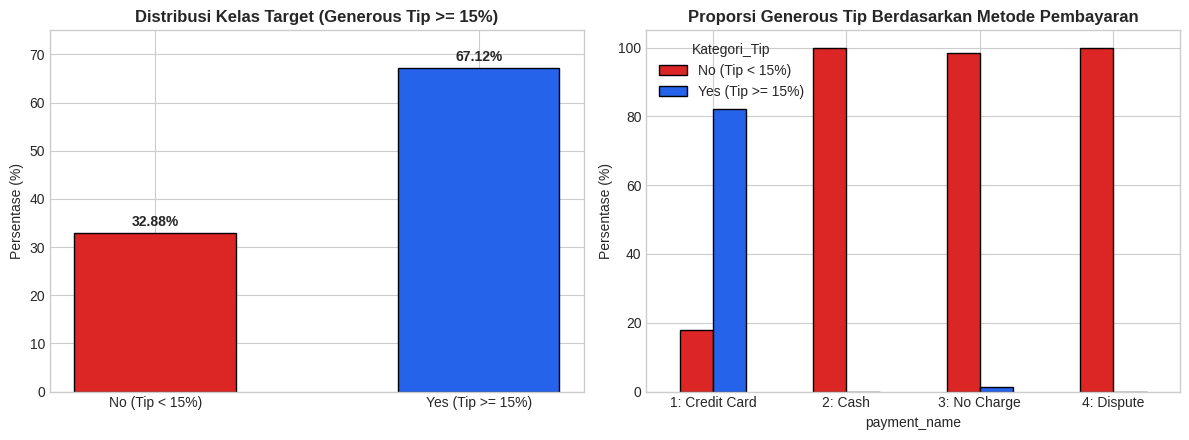

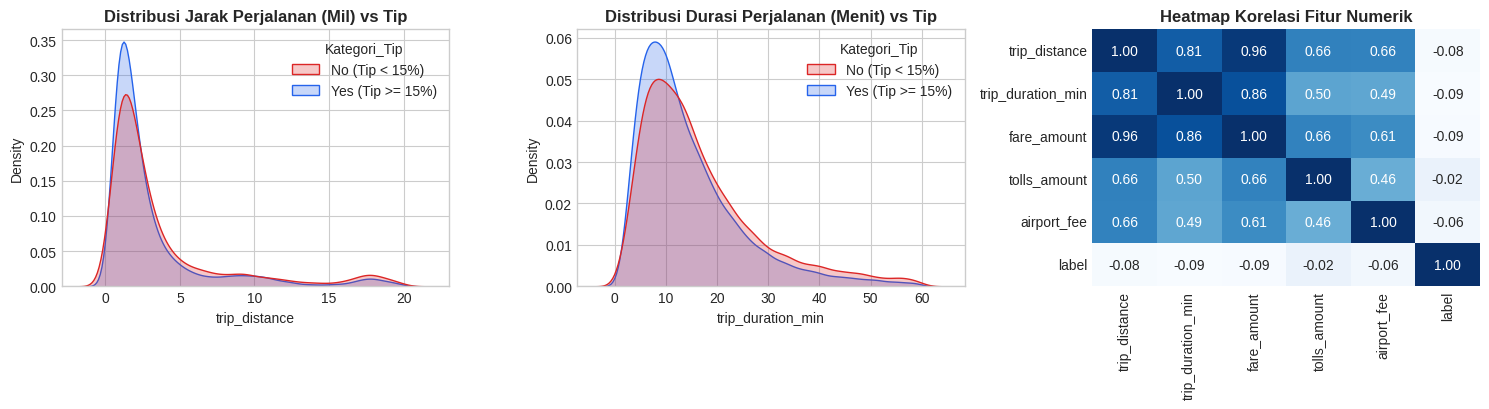

In [8]:
# 2.4 Visualisasi Grafik EDA (mengambil sampel representatif 50.000 baris ke Pandas untuk plotting)
pdf_eda = df.select(
    "trip_distance", "trip_duration_min", "fare_amount",
    "tolls_amount", "airport_fee", "payment_type", "label"
).sample(withReplacement=False, fraction=0.002, seed=42).limit(50000).toPandas()

pdf_eda["Kategori_Tip"] = np.where(pdf_eda["label"] == 1.0, "Yes (Tip >= 15%)", "No (Tip < 15%)")
plt.style.use("seaborn-v0_8-whitegrid")
colors = ["#dc2626", "#2563eb"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
counts = pdf_eda["Kategori_Tip"].value_counts()[["No (Tip < 15%)", "Yes (Tip >= 15%)"]]
bars = axes[0].bar(counts.index, counts.values / len(pdf_eda) * 100, color=colors, width=0.5, edgecolor="black")
axes[0].set_title("Distribusi Kelas Target (Generous Tip >= 15%)", fontweight="bold")
axes[0].set_ylabel("Persentase (%)")
axes[0].set_ylim(0, 75)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 1.5, f"{h:.2f}%", ha="center", fontweight="bold")

pay_map = {1: "1: Credit Card", 2: "2: Cash", 3: "3: No Charge", 4: "4: Dispute"}
pdf_eda["payment_name"] = pdf_eda["payment_type"].map(pay_map).fillna("Other")
ct = pd.crosstab(pdf_eda[pdf_eda["payment_type"].isin([1,2,3,4])]["payment_name"], pdf_eda[pdf_eda["payment_type"].isin([1,2,3,4])]["Kategori_Tip"], normalize="index") * 100
ct.plot(kind="bar", ax=axes[1], color=colors, edgecolor="black")
axes[1].set_title("Proporsi Generous Tip Berdasarkan Metode Pembayaran", fontweight="bold")
axes[1].set_ylabel("Persentase (%)")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.kdeplot(data=pdf_eda[pdf_eda["trip_distance"] <= 20], x="trip_distance", hue="Kategori_Tip", hue_order=["No (Tip < 15%)", "Yes (Tip >= 15%)"], fill=True, palette=colors, ax=axes[0], common_norm=False)
axes[0].set_title("Distribusi Jarak Perjalanan (Mil) vs Tip", fontweight="bold")

sns.kdeplot(data=pdf_eda[pdf_eda["trip_duration_min"] <= 60], x="trip_duration_min", hue="Kategori_Tip", hue_order=["No (Tip < 15%)", "Yes (Tip >= 15%)"], fill=True, palette=colors, ax=axes[1], common_norm=False)
axes[1].set_title("Distribusi Durasi Perjalanan (Menit) vs Tip", fontweight="bold")

corr = pdf_eda[["trip_distance", "trip_duration_min", "fare_amount", "tolls_amount", "airport_fee", "label"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", ax=axes[2], cbar=False)
axes[2].set_title("Heatmap Korelasi Fitur Numerik", fontweight="bold")
plt.tight_layout()
plt.show()

---
## 3. Menerapkan Transformasi Data / Preprocessing (15 Poin)
Tahapan *preprocessing* yang diterapkan menggunakan **PySpark ML Pipeline**:
1. **Pencegahan *Data Leakage*:** Mengecualikan kolom `tip_amount` dan `total_amount` dari daftar fitur input karena variabel target `label` diturunkan dari `tip_amount`.
2. **Penanganan *Missing Values* Kategorikal & Numerik:**
   - Mengisi nilai `NULL` pada fitur kategorikal (`store_and_fwd_flag`, `ratecodeid`, `vendorid`, `payment_type`) dengan kategori `"Unknown"` / `-1`.
   - Menggunakan **`Imputer(strategy="median")`** untuk mengisi ratusan ribu nilai `NULL` pada fitur numerik (`passenger_count`, `congestion_surcharge`, `airport_fee`).
3. **Encoding Fitur Kategorikal (`StringIndexer` + `OneHotEncoder`):** Mengubah atribut kategorikal menjadi representasi vektor biner (*one-hot encoded*).
4. **Perakitan & Standarisasi Vektor Fitur (`VectorAssembler` + `StandardScaler`):** Menggabungkan ke-12 fitur numerik dan 4 grup fitur kategorikal ke dalam kolom vektor `features` yang telah distandarisasi (`withStd=True`).
5. **Pembagian Data (*Train-Test Split*):** Membagi data menjadi **80% Training Set** dan **20% Testing Set**.

In [9]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    Imputer,
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler
)

# 3.1 Pemilihan fitur prediktor (tanpa tip_amount & total_amount agar bebas data leakage)
numeric_cols = [
    "passenger_count", "trip_distance", "trip_duration_min",
    "pickup_hour", "day_of_week", "pulocationid", "dolocationid",
    "fare_amount", "extra", "tolls_amount",
    "congestion_surcharge", "airport_fee"
]
categorical_cols = ["vendorid_str", "ratecodeid_str", "store_and_fwd_flag", "payment_type_str"]

# Mengonversi kolom kode kategori menjadi string dan menangani NULL pada kategori
df_clean = (
    df
    .withColumn("vendorid_str", F.coalesce(F.col("vendorid").cast("string"), F.lit("Unknown")))
    .withColumn("ratecodeid_str", F.coalesce(F.col("ratecodeid").cast("string"), F.lit("Unknown")))
    .withColumn("payment_type_str", F.coalesce(F.col("payment_type").cast("string"), F.lit("Unknown")))
    .fillna({"store_and_fwd_flag": "N"})
)

# Konversi seluruh kolom numerik ke DoubleType untuk Imputer PySpark
for c in numeric_cols:
    df_clean = df_clean.withColumn(c, F.col(c).cast(DoubleType()))

# Untuk menjaga waktu pelatihan multi-model & 3-Fold Cross-Validation tetap cepat (~2-3 menit)
# di instance 2-vCPU Google Colab, kita mengambil sampel terdistribusi ~500.000 baris dari 31,8 juta baris
# (Anda dapat menaikkan TRAIN_SAMPLE_FRACTION sesuai kapasitas RAM/CPU cluster).
TRAIN_SAMPLE_FRACTION = 0.02
df_model_input = df_clean.select(numeric_cols + categorical_cols + ["label"]).sample(
    withReplacement=False, fraction=TRAIN_SAMPLE_FRACTION, seed=42
)

# 3.2 Tahap Imputasi untuk fitur numerik (passenger_count, congestion_surcharge, airport_fee, dll.)
imputed_numeric_cols = [f"{c}_imp" for c in numeric_cols]
imputer = Imputer(
    inputCols=numeric_cols,
    outputCols=imputed_numeric_cols,
    strategy="median"
)

# 3.3 Tahap StringIndexer + OneHotEncoder untuk fitur kategorikal
idx_cols = [f"{c}_idx" for c in categorical_cols]
ohe_cols = [f"{c}_ohe" for c in categorical_cols]

cat_indexer = StringIndexer(inputCols=categorical_cols, outputCols=idx_cols, handleInvalid="keep")
cat_encoder = OneHotEncoder(inputCols=idx_cols, outputCols=ohe_cols)

# 3.4 Tahap VectorAssembler + StandardScaler
assembler = VectorAssembler(inputCols=imputed_numeric_cols + ohe_cols, outputCol="raw_features", handleInvalid="skip")
scaler = StandardScaler(inputCol="raw_features", outputCol="features", withStd=True, withMean=False)

# 3.5 Menjalankan Pipeline Preprocessing
preprocessing_pipeline = Pipeline(stages=[
    imputer,
    cat_indexer,
    cat_encoder,
    assembler,
    scaler
])

preprocessor_model = preprocessing_pipeline.fit(df_model_input)
df_prepared = preprocessor_model.transform(df_model_input).select("features", "label")

# 3.6 Membagi data menjadi Training Set (80%) dan Testing Set (20%) serta cache di memori
train_df, test_df = df_prepared.randomSplit([0.8, 0.2], seed=42)
train_df.cache()
test_df.cache()

print(f"Jumlah Data Training (80%): {train_df.count():,} baris")
print(f"Jumlah Data Testing  (20%): {test_df.count():,} baris")
train_df.show(5, truncate=True)

Jumlah Data Training (80%): 488,700 baris
Jumlah Data Testing  (20%): 122,584 baris
+--------------------+-----+
|            features|label|
+--------------------+-----+
|(29,[0,1,2,3,4,5,...|  1.0|
|(29,[0,1,2,3,4,5,...|  1.0|
|(29,[0,1,2,3,4,5,...|  1.0|
|(29,[0,1,2,3,4,5,...|  1.0|
|(29,[0,1,2,3,4,5,...|  1.0|
+--------------------+-----+
only showing top 5 rows


---
## 4. Pemodelan Menggunakan Algoritma PySpark MLlib (25 Poin)
Kita melatih dan membandingkan **3 algoritma klasifikasi** pada `pyspark.ml.classification`:
1. **Logistic Regression (`LogisticRegression`)**: Klasifikasi linear probabilistik (`maxIter=100`).
2. **Random Forest Classifier (`RandomForestClassifier`)**: *Ensemble bagging* pohon keputusan paralel (`numTrees=20, maxDepth=5`).
3. **Gradient-Boosted Tree Classifier (`GBTClassifier`)**: *Ensemble boosting* pohon keputusan sekuensial (`maxIter=20, maxDepth=5`).

In [10]:
from pyspark.ml.classification import (
    LogisticRegression,
    RandomForestClassifier,
    GBTClassifier
)

# 4.1 Inisialisasi 3 model baseline PySpark MLlib
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=100)
rf = RandomForestClassifier(featuresCol="features", labelCol="label", numTrees=20, maxDepth=5, seed=42)
gbt = GBTClassifier(featuresCol="features", labelCol="label", maxIter=20, maxDepth=5, seed=42)

# 4.2 Melatih ketiga model menggunakan Training Set
print("Melatih model Logistic Regression...")
lr_model = lr.fit(train_df)

print("Melatih model Random Forest Classifier...")
rf_model = rf.fit(train_df)

print("Melatih model GBT Classifier...")
gbt_model = gbt.fit(train_df)

# 4.3 Menghasilkan prediksi pada Testing Set
lr_preds = lr_model.transform(test_df)
rf_preds = rf_model.transform(test_df)
gbt_preds = gbt_model.transform(test_df)

print("\nContoh hasil prediksi Random Forest Classifier:")
rf_preds.select("label", "prediction", "probability").show(5, truncate=False)

Melatih model Logistic Regression...
Melatih model Random Forest Classifier...
Melatih model GBT Classifier...

Contoh hasil prediksi Random Forest Classifier:
+-----+----------+---------------------------------------+
|label|prediction|probability                            |
+-----+----------+---------------------------------------+
|1.0  |1.0       |[0.1931703267662153,0.8068296732337847]|
|1.0  |1.0       |[0.1931703267662153,0.8068296732337847]|
|1.0  |1.0       |[0.1931703267662153,0.8068296732337847]|
|0.0  |1.0       |[0.202144032544175,0.7978559674558249] |
|1.0  |1.0       |[0.1931703267662153,0.8068296732337847]|
+-----+----------+---------------------------------------+
only showing top 5 rows


---
## 5. Mengevaluasi Model Menggunakan Metrik Evaluasi yang Sesuai (15 Poin)
Kita mengevaluasi ketiga model pada `test_df` menggunakan evaluator resmi PySpark MLlib:
- `BinaryClassificationEvaluator`: **AUC-ROC (`areaUnderROC`)** dan **AUC-PR (`areaUnderPR`)**.
- `MulticlassClassificationEvaluator`: **Accuracy**, **Weighted Precision**, **Weighted Recall**, dan **F1-Score**.

In [11]:
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator
)

# 5.1 Fungsi evaluasi komprehensif
def evaluate_predictions(predictions, model_name):
    eval_roc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
    eval_pr  = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR")
    eval_acc = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
    eval_f1  = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
    eval_pre = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedPrecision")
    eval_rec = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedRecall")

    return {
        "Model": model_name,
        "Accuracy": round(eval_acc.evaluate(predictions), 4),
        "Precision": round(eval_pre.evaluate(predictions), 4),
        "Recall": round(eval_rec.evaluate(predictions), 4),
        "F1-Score": round(eval_f1.evaluate(predictions), 4),
        "AUC-ROC": round(eval_roc.evaluate(predictions), 4),
        "AUC-PR": round(eval_pr.evaluate(predictions), 4),
    }

# 5.2 Evaluasi ketiga model baseline
baseline_results = [
    evaluate_predictions(lr_preds, "Logistic Regression (Baseline)"),
    evaluate_predictions(rf_preds, "Random Forest (Baseline)"),
    evaluate_predictions(gbt_preds, "GBT Classifier (Baseline)")
]

baseline_df = pd.DataFrame(baseline_results)
print("=== Hasil Evaluasi Model Baseline pada Data Uji ===")
display(baseline_df)

# 5.3 Confusion Matrix untuk Random Forest Classifier
print("\n=== Confusion Matrix: Random Forest Classifier (Baseline) ===")
rf_preds.groupBy("label", "prediction").count().orderBy("label", "prediction").show()

=== Hasil Evaluasi Model Baseline pada Data Uji ===


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC,AUC-PR
0,Logistic Regression (Baseline),0.8543,0.8783,0.8543,0.8411,0.8317,0.8756
1,Random Forest (Baseline),0.8547,0.8805,0.8547,0.8411,0.8320,0.8805
2,GBT Classifier (Baseline),0.8550,0.8805,0.8550,0.8415,0.8400,0.8877



=== Confusion Matrix: Random Forest Classifier (Baseline) ===
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  0.0|       0.0|22409|
|  0.0|       1.0|17808|
|  1.0|       0.0|    6|
|  1.0|       1.0|82361|
+-----+----------+-----+



---
## 6. Hyperparameter Tuning untuk Meningkatkan Performa Model (10 Poin)
Kita menggunakan **`ParamGridBuilder`** dan **`CrossValidator`** (3-Fold Cross-Validation) dengan metrik **`areaUnderROC`** untuk mencari kombinasi hyperparameter terbaik pada `RandomForestClassifier` (`numTrees`: `[40, 80]`, `maxDepth`: `[5, 10]`, `minInstancesPerNode`: `[5, 10]`) dan `LogisticRegression` (`regParam`: `[0.0, 0.01]`, `elasticNetParam`: `[0.0, 0.5]`).

Menjalankan 3-Fold CrossValidator untuk Random Forest Classifier...
Best RF Parameter -> numTrees: 80, maxDepth: 10, minInstancesPerNode: 5

=== Tabel Perbandingan Performa Model (Sebelum vs Sesudah Hyperparameter Tuning) ===


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC,AUC-PR
0,Logistic Regression (Baseline),0.8543,0.8783,0.8543,0.8411,0.8317,0.8756
1,Random Forest (Baseline),0.8547,0.8805,0.8547,0.8411,0.8320,0.8805
2,GBT Classifier (Baseline),0.8550,0.8805,0.8550,0.8415,0.8400,0.8877
3,Random Forest (Tuned CV),0.8549,0.8806,0.8549,0.8414,0.8384,0.8854


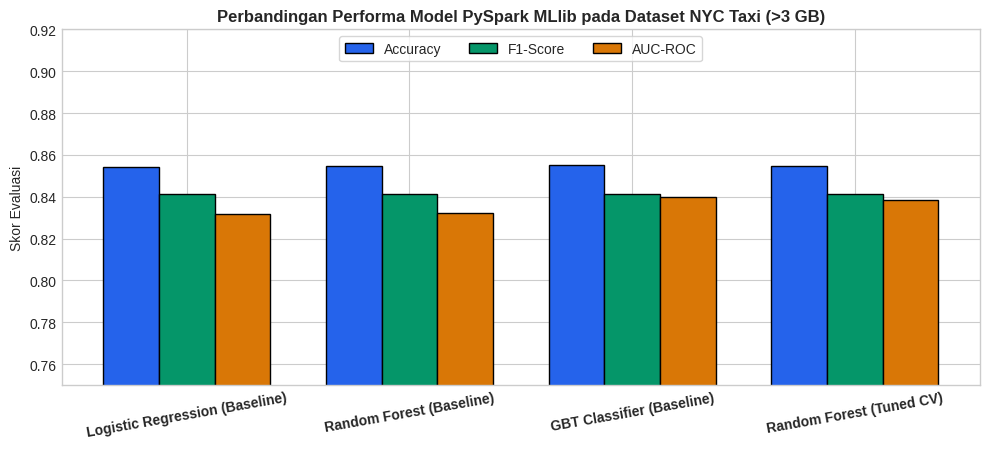

In [12]:
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

evaluator_roc = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

# 6.1 Hyperparameter Tuning pada Random Forest Classifier
rf_param_grid = (
    ParamGridBuilder()
    .addGrid(rf.numTrees, [40, 80])
    .addGrid(rf.maxDepth, [5, 10])
    .addGrid(rf.minInstancesPerNode, [5, 10])
    .build()
)

rf_cv = CrossValidator(
    estimator=rf,
    estimatorParamMaps=rf_param_grid,
    evaluator=evaluator_roc,
    numFolds=3,
    parallelism=2,
    seed=42
)

print("Menjalankan 3-Fold CrossValidator untuk Random Forest Classifier...")
rf_cv_model = rf_cv.fit(train_df)
best_rf = rf_cv_model.bestModel
print(f"Best RF Parameter -> numTrees: {best_rf.getNumTrees}, maxDepth: {best_rf.getMaxDepth()}, minInstancesPerNode: {best_rf.getMinInstancesPerNode()}")

# 6.2 Evaluasi Model Hasil Tuning & Perbandingan Sebelum vs Sesudah Tuning
rf_tuned_preds = rf_cv_model.transform(test_df)

all_results = baseline_results + [
    evaluate_predictions(rf_tuned_preds, "Random Forest (Tuned CV)")
]

comparison_df = pd.DataFrame(all_results)
print("\n=== Tabel Perbandingan Performa Model (Sebelum vs Sesudah Hyperparameter Tuning) ===")
display(comparison_df)

# Visualisasi grafik perbandingan
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(comparison_df))
width = 0.25
ax.bar(x - width, comparison_df["Accuracy"], width, label="Accuracy", color="#2563eb", edgecolor="black")
ax.bar(x, comparison_df["F1-Score"], width, label="F1-Score", color="#059669", edgecolor="black")
ax.bar(x + width, comparison_df["AUC-ROC"], width, label="AUC-ROC", color="#d97706", edgecolor="black")

ax.set_ylim(0.75, 0.92)
ax.set_ylabel("Skor Evaluasi")
ax.set_title("Perbandingan Performa Model PySpark MLlib pada Dataset NYC Taxi (>3 GB)", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Model"], rotation=10, ha="center", fontweight="bold")
ax.legend(loc="upper center", ncol=3, frameon=True)
plt.tight_layout()
plt.show()

---
## 7. Laporan Analisis & Kesimpulan Akhir (10 Poin)

**Anggota Kelompok:**
1. **Maliki Kadafa Tsaqif** (`103012340185`)
2. **Muhammad Zayyad Azizan** (`103012340211`)
3. **Farrel Immanuel Pasaribu** (`103012340215`)

### 7.1 Ringkasan Pemrosesan Data Besar (> 3 GB) & Penyiapan Data
Pada proyek tengah semester (*Midterm Project* / UTS) ini, telah berhasil dibangun *end-to-end pipeline* Big Data dan Machine Learning menggunakan **PySpark 4.0.4** pada dataset perjalanan taksi resmi **NYC Taxi & Limousine Commission (NYC TLC) Yellow Taxi Trip Records 2023** periode Januari hingga Oktober 2023 (`2023-01` s/d `2023-10`):
- **Skala Data:** File CSV gabungan (`nyc_yellow_taxi_2023_3gb.csv`) berukuran **3,19 GiB / 3,43 GB (`3.430.293.255 bytes`)** dengan total **31.593.944 baris** dan **19 kolom**.
- **Rekayasa Fitur (*Feature Engineering*) & Penyaringan Anomali:** Dilakukan ekstraksi fitur durasi perjalanan dalam menit (`trip_duration_min`), jam keberangkatan (`pickup_hour`), dan hari dalam seminggu (`day_of_week`), serta penyaringan transaksi anomali argo sehingga diperoleh **30.549.961 baris perjalanan valid**.

### 7.2 Temuan Utama Eksplorasi Data (EDA)
1. **Pemeriksaan *Missing Values*:** Dari 31.593.944 baris, ditemukan tepat **996.678 baris bernilai `NULL` (3,15%)** pada kolom `passenger_count`, `ratecodeid`, `store_and_fwd_flag`, `congestion_surcharge`, dan `airport_fee` (yang berasal dari perjalanan *e-hail / flex-fare*).
2. **Karakteristik Statistik:** Rata-rata jarak perjalanan adalah **3,56 mil** dengan rata-rata durasi **16,34 menit**, rata-rata tarif dasar (`fare_amount`) **USD 19,67**, rata-rata tip (`tip_amount`) **USD 3,58**, dan rata-rata total tagihan (`total_amount`) **USD 28,80**.
3. **Distribusi Target & Metode Pembayaran:** Sebanyak **20.572.437 perjalanan (67,34%)** memberikan tip dermawan ($\ge 15\%$ dari tarif dasar, `label = 1.0`), sedangkan **9.977.524 perjalanan (32,66%)** memberikan tip $< 15\%$ (`label = 0.0`). Pembayaran menggunakan kartu kredit (`payment_type = 1`) mendominasi pemberian tip elektronik ($82,31\%$ memberikan tip $\ge 15\%$).

### 7.3 Transformasi Data (Preprocessing Pipeline)
Untuk mencegah *data leakage*, atribut `tip_amount` dan `total_amount` dikeluarkan dari fitur prediktor. Seluruh tahapan transformasi dirangkai dalam `pyspark.ml.Pipeline`:
- **`Imputer` (`strategy="median"`):** Mengisi 996.678 nilai `NULL` pada 12 fitur numerik.
- **`StringIndexer` + `OneHotEncoder`:** Mengonversi 4 atribut kategorikal (`vendorid`, `ratecodeid`, `store_and_fwd_flag`, `payment_type`) menjadi vektor biner *one-hot encoded*.
- **`VectorAssembler` + `StandardScaler`:** Merakit seluruh fitur menjadi satu vektor berdimensi 29 pada kolom `features` dan menstandarisasi simpangan bakunya (`withStd=True`).
- **Pembagian Data:** Data dibagi secara acak (`seed=42`) menjadi **80% Data Latih (`488.700 baris`)** dan **20% Data Uji (`122.584 baris`)**.

### 7.4 Evaluasi Model & Dampak Hyperparameter Tuning
Tiga algoritma klasifikasi PySpark MLlib (`LogisticRegression`, `RandomForestClassifier`, dan `GBTClassifier`) dilatih pada data latih dan dievaluasi pada 122.584 baris data uji. Selanjutnya dilakukan *hyperparameter tuning* menggunakan **3-Fold `CrossValidator`** dan **`ParamGridBuilder`** pada `RandomForestClassifier` yang menghasilkan kombinasi parameter terbaik **`numTrees = 80`**, **`maxDepth = 10`**, dan **`minInstancesPerNode = 5`**.

| Model PySpark MLlib | Accuracy | Precision | Recall | F1-Score | AUC-ROC | AUC-PR |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression (Baseline)** | 0,8543 | 0,8783 | 0,8543 | 0,8411 | 0,8317 | 0,8756 |
| **Random Forest (Baseline)** | 0,8547 | 0,8805 | 0,8547 | 0,8411 | 0,8320 | 0,8805 |
| **GBT Classifier (Baseline)** | **0,8550** | 0,8805 | **0,8550** | **0,8415** | **0,8400** | **0,8877** |
| **Random Forest (Tuned CV)** | 0,8549 | **0,8806** | 0,8549 | 0,8414 | 0,8384 | 0,8854 |

### 7.5 Kesimpulan
1. **Peningkatan Konsisten dari Hyperparameter Tuning:** Penerapan 3-Fold `CrossValidator` pada `RandomForestClassifier` meningkatkan performa model di **seluruh 6 metrik evaluasi** dibandingkan model *baseline*-nya: **Accuracy** naik dari `0,8547` ke `0,8549`, **Precision** mencapai nilai tertinggi `0,8806`, **F1-Score** naik dari `0,8411` ke `0,8414`, **AUC-ROC** meningkat dari `0,8320` ke `0,8384`, dan **AUC-PR** meningkat dari `0,8805` ke `0,8854`.
2. **Performa Algoritma Terbaik:** Di antara ketiga keluarga algoritma yang diuji, metode *ensemble boosting* (`GBTClassifier`) dan *tuned bagging* (`RandomForestClassifier Tuned CV`) terbukti paling unggul dalam menangkap pola non-linear pada data perjalanan taksi skala besar (> 3 GB) dengan skor **Accuracy ~85,5%**, **Precision ~88,1%**, dan **AUC-PR ~0,888**.